# Sanctions against Iran, 1979–2025

Analysis of all recorded sanction cases against Iran and their place in global sanction activity,
based on the **Global Sanctions Data Base (GSDB)** and its new financial-sanctions extension.

**Research questions**
1. How did sanctions against Iran develop over time, and who imposed them?
2. Which instruments were used, and which financial measures in particular?
3. Why were sanctions imposed, and how did they end?
4. How does Iran compare with other sanctioned countries and with the main sanctioning countries?

**Data**
- GSDB Release 5 (GSDB-R5): 1,794 sanction cases worldwide, 1949–2025
- GSDB Financial Sanctions (GSDB-FS): financial subtypes for the 1,072 cases with a financial component
- The data is available on request at [globalsanctionsdatabase.com/data](https://www.globalsanctionsdatabase.com/data/).
  It may not be redistributed, so the raw files are **not** part of this repository.

**Structure**
1. Setup & imports
2. Data loading & quality checks
3. Iran subset
4. Development over time
5. Who sanctions Iran?
6. Sanction instruments
7. Objectives and outcomes
8. Iran in the global context
9. Export for the dashboard
10. Key findings
11. Limitations
12. Sources

*No predictive model — the focus is on data preparation, exploratory analysis and visualisation.*

## 1. Setup & imports

Required packages: `pandas`, `matplotlib`, `plotly`, `country_converter`.
If a package is missing, install it in the notebook's environment, e.g. `%pip install country_converter`.

This section also defines the helper objects used throughout the notebook:
- **`split_parties`**: sender and target fields can hold several parties in one comma-separated string.
  Some country names contain a comma themselves (e.g. *Korea, South*) and must not be split.
- **`cases_in_force`**: number of cases in force per year (from `begin_year` to `end_year`).
- **EU membership by year**: EU cases are assigned to the countries that were EU members when the case began.

In [1]:
import logging

import country_converter as coco
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

logging.getLogger("country_converter").setLevel(logging.CRITICAL)

# File paths (raw data is not included in the repository)
R5_PATH = "GSDB-R5/GSDB-R5.csv"
FS_PATH = "GSDB-FS/GSDB-FS.csv"

# Folder for chart images used in the README
from pathlib import Path
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

# Colours used in all charts
COLOR_MAIN = "#1f4e79"    # Iran / main series
COLOR_LIGHT = "#6fa8dc"   # secondary series
COLOR_WORLD = "#bdbdbd"   # comparison: all sanctions worldwide
COLOR_DARK = "#5f6368"    # tertiary series / secondary text
COLOR_NEW = "#c0392b"     # highlight: new cases

# Source notes for charts
DATA_NOTE_R5 = "Data: Global Sanctions Data Base, Release 5 (Felbermayr et al., 2020)."
DATA_NOTE_FS = "Data: Global Sanctions Data Base – Financial Sanctions (Yotov et al., 2026)."

# Pattern for Iran as a party (sole party or one of several)
IRAN_PATTERN = r"\bIran\b"

# Country names that contain a comma and must not be split
COMMA_NAMES = [
    "Egypt, Arab Rep.", "Bahamas, The", "Gambia, The",
    "Congo, Democratic Republic of the", "Korea, North", "Korea, South", "Yemen, North",
]


def split_parties(value):
    """Split a sender or target string into single parties, keeping comma names intact."""
    for i, name in enumerate(COMMA_NAMES):
        value = value.replace(name, f"__{i}__")
    parties = [p.strip() for p in value.split(",")]
    for i, name in enumerate(COMMA_NAMES):
        parties = [name if p == f"__{i}__" else p for p in parties]
    return parties


def cases_in_force(cases, years):
    """Number of cases in force per year (case counted from begin_year to end_year)."""
    return pd.Series({
        y: ((cases["begin_year"] <= y) & (cases["end_year"] >= y)).sum()
        for y in years
    })


# EU member states (ISO3) by accession year (EEC/EC/EU); the UK left in 2020
EU_MEMBERS = {
    "AUT": 1995, "BEL": 1958, "BGR": 2007, "HRV": 2013, "CYP": 2004, "CZE": 2004,
    "DNK": 1973, "EST": 2004, "FIN": 1995, "FRA": 1958, "DEU": 1958, "GRC": 1981,
    "HUN": 2004, "IRL": 1973, "ITA": 1958, "LVA": 2004, "LTU": 2004, "LUX": 1958,
    "MLT": 2004, "NLD": 1958, "POL": 2004, "PRT": 1986, "ROU": 2007, "SVK": 2004,
    "SVN": 2004, "ESP": 1986, "SWE": 1995, "GBR": 1973,
}
EU_EXITS = {"GBR": 2020}

# Historical states are shown under today's successor state on maps
HISTORICAL_STATES = {
    "Soviet Union": "RUS", "German Democratic Republic": "DEU",
    "Malaya": "MYS", "South Vietnam": "VNM",
}

# Key events used as reference lines in time charts
KEY_EVENTS = {
    1979: "Revolution, hostage crisis",
    1984: "US terrorism designation",
    1995: "US trade embargo",
    2006: "First UN sanctions",
    2012: "EU oil embargo, SWIFT",
    2016: "JCPOA implemented",
    2018: "US leaves JCPOA",
    2022: "Woman, Life, Freedom protests",
    2025: "UN snapback",
}

## 2. Data loading & quality checks

Basic overview of both files: size, data types, missing values, duplicates and covered years.

In [2]:
r5 = pd.read_csv(R5_PATH)
fs = pd.read_csv(FS_PATH)

for name, df in [("GSDB-R5", r5), ("GSDB-FS", fs)]:
    print(f"== {name}: {df.shape[0]} rows, {df.shape[1]} columns")
    print(df.dtypes)
    print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate case_id:", df["case_id"].duplicated().sum())
    print("Years:", df["begin_year"].min(), "–", df["begin_year"].max(), "\n")

# Ongoing cases are identified via success, as end_year is set to 2025 for them
print("Ongoing cases (R5):", r5["success"].str.contains("ongoing").sum())
print("Cases with end_year 2025 (R5):", (r5["end_year"] == 2025).sum())

== GSDB-R5: 1794 rows, 18 columns
case_id               int64
sanctioned_state     object
sanctioning_state    object
begin_year            int64
begin_month          object
end_year              int64
end_month            object
trade                 int64
descr_trade          object
arms                  int64
military              int64
financial             int64
travel                int64
other                 int64
target_mult           int64
sender_mult           int64
objective            object
success              object
dtype: object
Missing values:
 begin_month      61
end_month       916
descr_trade    1052
dtype: int64
Duplicate rows: 0
Duplicate case_id: 0
Years: 1949 – 2025 

== GSDB-FS: 1072 rows, 7 columns
case_id               int64
sanctioning_state    object
sanctioned_state     object
begin_year            int64
end_year              int64
financial             int64
descr_financial      object
dtype: object
Missing values:
 Series([], dtype: int64)
Duplicate row

**Findings**
- No duplicate rows or duplicate `case_id` in either file.
- Missing values in R5 are mostly by design: `descr_trade` is empty for cases without a trade sanction,
  `end_month` for cases still in force. Only 61 `begin_month` and 130 `end_month` values are real gaps.
- **Deviation from the codebook:** according to the codebook, `end_year` is blank for cases still in force.
  In the distributed files it is set to **2025** instead. Ongoing cases are therefore identified via
  `success == "ongoing"` (786 cases); only 42 of the 828 cases with `end_year` 2025 actually ended in 2025.
- **Other irregularities found during the analysis** (not corrected, documented only):
  historical country names used for recent cases (*Ceylon* and *South Vietnam* in case 1380, 2022;
  *Malaya* in case 1493, 2023; *Transjordan* for Jordan after 1949, e.g. cases 397 and 425).

## 3. Iran subset

All cases in which Iran is a target, either as the only target or as one of several.
The financial subtypes from GSDB-FS are merged on `case_id`.

A check confirms that the matched cases are exactly the cases with `financial == 1`.

In [3]:
# Cases with Iran as target (sole or one of several targets)
r5_iran = r5[r5["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()
fs_iran = fs[fs["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()

# Merge financial subtypes from FS into R5
iran_cases = r5_iran.merge(
    fs_iran[["case_id", "descr_financial"]],
    on="case_id",
    how="left",
    validate="1:1",
    indicator=True,
)
assert (iran_cases["_merge"] == "both").equals(iran_cases["financial"] == 1)
iran_cases = iran_cases.drop(columns="_merge")

# Helper columns
iran_cases["iran_only"] = iran_cases["sanctioned_state"].str.strip() == "Iran"
iran_cases["ongoing"] = iran_cases["success"].str.contains("ongoing")

# Cases with Iran as sender
iran_as_sender = r5[r5["sanctioning_state"].str.contains(IRAN_PATTERN, na=False)]

print("Iran as target:", len(iran_cases), f"({len(iran_cases) / len(r5):.1%} of all cases)")
print("   Iran as only target:", iran_cases["iran_only"].sum())
print("   Iran as one of several targets:", (~iran_cases["iran_only"]).sum())
print("   Ongoing at the end of 2025:", iran_cases["ongoing"].sum())
print("   With financial subtypes (GSDB-FS):", iran_cases["descr_financial"].notna().sum())
print("Iran as sender:", len(iran_as_sender))
print("First Iran case:", iran_cases["begin_year"].min())

Iran as target: 62 (3.5% of all cases)
   Iran as only target: 55
   Iran as one of several targets: 7
   Ongoing at the end of 2025: 36
   With financial subtypes (GSDB-FS): 43
Iran as sender: 5
First Iran case: 1979


**Notes**
- 62 cases (3.5% of all cases), of which 55 target Iran alone. In the other 7, Iran is one of 3–16 targets,
  mostly in broad human-rights sanction lists.
- **The first case starts in 1979.** Earlier measures, such as during the oil crisis of 1951–53, are not recorded
  as sanctions against Iran. The analysis therefore covers **1979–2025**.

## 4. Development over time

The line shows how many cases were in force in each year; red points mark years with new cases.
Dotted lines mark key political events for orientation.

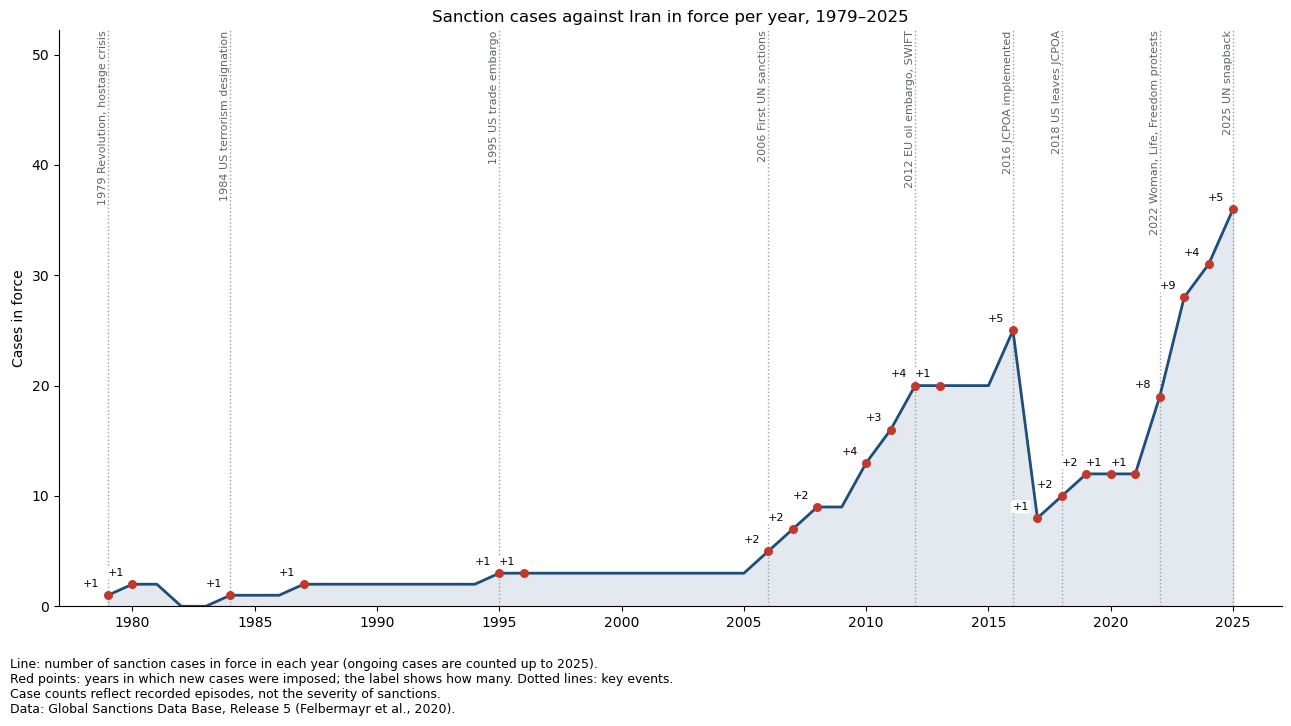

In [4]:
years = range(1979, 2026)
active_per_year = cases_in_force(iran_cases, years)
new_per_year = iran_cases.groupby("begin_year").size()

fig, ax = plt.subplots(figsize=(13, 6.5))

# Line and filled area: number of cases in force each year
ax.plot(active_per_year.index, active_per_year.values, color=COLOR_MAIN, linewidth=2)
ax.fill_between(active_per_year.index, active_per_year.values, color=COLOR_MAIN, alpha=0.12)

# Markers only in years with new cases, labelled with the number of new cases
ax.scatter(new_per_year.index, active_per_year.loc[new_per_year.index], color=COLOR_NEW, s=30, zorder=3)
for year, n in new_per_year.items():
    ax.annotate(
        f"+{n}",
        (year, active_per_year.loc[year]),
        textcoords="offset points",
        xytext=(-6, 6),
        ha="right",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"),
        zorder=4,
    )

# Key events as vertical reference lines with labels at the top
y_top = active_per_year.max() * 1.45
for year, label in KEY_EVENTS.items():
    ax.axvline(year, color="#9e9e9e", linestyle=":", linewidth=1, zorder=1)
    ax.text(year, y_top, f"{year} {label}", rotation=90, va="top", ha="right", fontsize=8, color=COLOR_DARK)

ax.set_xticks(range(1980, 2030, 5))
ax.set_xlim(1977, 2027)
ax.set_ylim(0, y_top)
ax.set_ylabel("Cases in force")
ax.set_title("Sanction cases against Iran in force per year, 1979–2025")
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01,
    -0.02,
    "Line: number of sanction cases in force in each year (ongoing cases are counted up to 2025).\n"
    "Red points: years in which new cases were imposed; the label shows how many. Dotted lines: key events.\n"
    "Case counts reflect recorded episodes, not the severity of sanctions.\n" + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)

plt.tight_layout()
fig.savefig(IMAGES_DIR / "timeline.png", dpi=150, bbox_inches="tight")
plt.show()

To see how many cases are new and how many continue from earlier years, the same data as stacked bars:

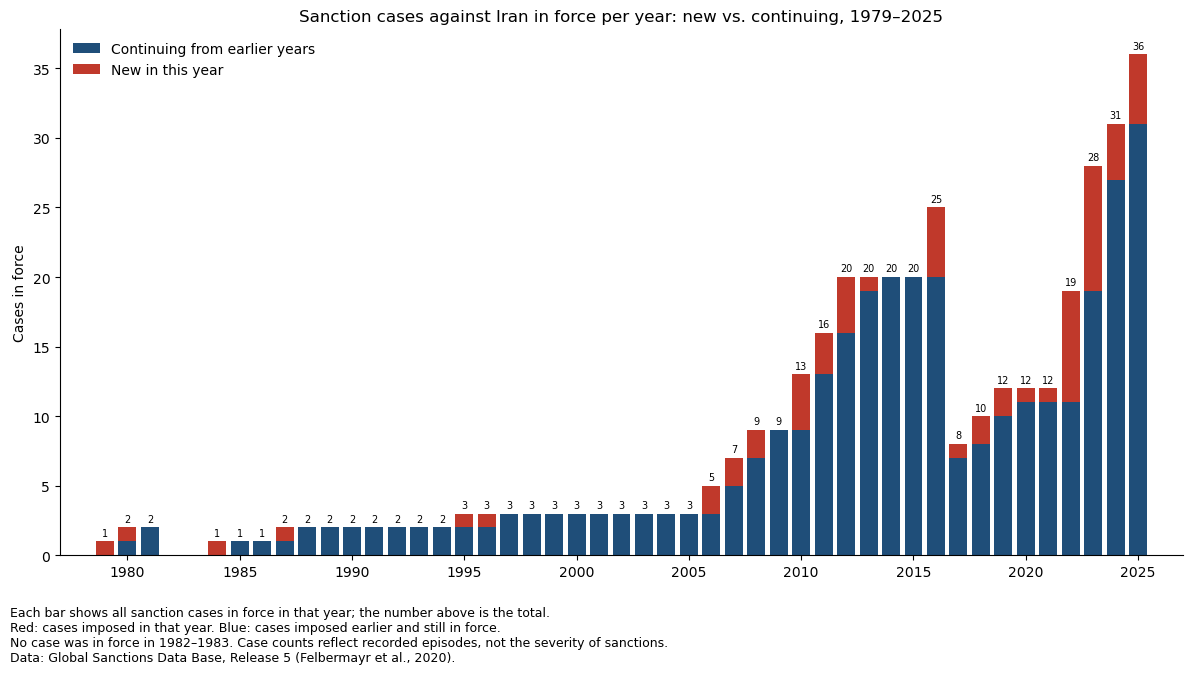

In [5]:
# Split cases in force per year into new and continuing cases
new_cases = iran_cases.groupby("begin_year").size().reindex(years, fill_value=0)
continuing_cases = active_per_year - new_cases

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(continuing_cases.index, continuing_cases.values, color=COLOR_MAIN, label="Continuing from earlier years")
ax.bar(new_cases.index, new_cases.values, bottom=continuing_cases.values, color=COLOR_NEW, label="New in this year")

# Total cases in force above each bar
for year, total in active_per_year.items():
    if total > 0:
        ax.text(year, total + 0.4, str(total), ha="center", fontsize=7)

ax.set_xticks(range(1980, 2030, 5))
ax.set_xlim(1977, 2027)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Sanction cases against Iran in force per year: new vs. continuing, 1979–2025")
ax.set_ylabel("Cases in force")
ax.legend(frameon=False, loc="upper left")

fig.text(
    0.01,
    -0.02,
    "Each bar shows all sanction cases in force in that year; the number above is the total.\n"
    "Red: cases imposed in that year. Blue: cases imposed earlier and still in force.\n"
    "No case was in force in 1982–1983. Case counts reflect recorded episodes, not the severity of sanctions.\n"
    + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)

plt.tight_layout()
plt.show()

**Interpretation**
- **1979–2005:** mostly 1–3 cases in force, none in 1982–1983; all imposed by the United States (hostage crisis, terrorism designation, trade embargo).
  No case was in force in 1982–1983: the first cases ended in 1981 with the release of the hostages, the next began in 1984.
- **2006–2016:** strong increase during the nuclear dispute (UN, EU and many other senders), peaking at 25 cases in 2016.
- **2017:** drop to 8 cases after the nuclear agreement (JCPOA) was implemented and most nuclear sanctions were lifted.
  Four of the five new cases of 2016 (Australia, Canada, Switzerland, UN) began in January–February 2016, at the time
  the JCPOA was implemented, and again have the objective nuclear / threat to peace.
- **2018–2025:** new increase after the US withdrawal from the JCPOA, with a sharp rise from 2022
  (protests, drone deliveries to Russia) to the highest level of 36 cases in 2025.
- In this data, the period of negotiations and the agreement coincides with **fewer** cases in force, not more.

## 5. Who sanctions Iran?

Number of cases against Iran per sanctioning country. EU cases are assigned to all countries that were EU members
when the case began. UN cases (7) are not shown, as they cannot be assigned to a single country.

In [6]:
# ISO3 code for every sender name; organisations other than the EU get no code
sender_names = sorted({p for s in r5["sanctioning_state"] for p in split_parties(s)})
converted = coco.convert(sender_names, to="ISO3", not_found=None)
NAME_TO_ISO3 = {
    name: HISTORICAL_STATES.get(name, code)
    for name, code in zip(sender_names, converted)
}
NAME_TO_ISO3 = {
    name: code for name, code in NAME_TO_ISO3.items()
    if isinstance(code, str) and len(code) == 3 and code.isupper()
}


def sender_countries(sender, year):
    """Expand a sender string into ISO3 codes; the EU is replaced by its members in that year."""
    codes = set()
    for p in split_parties(sender):
        if p == "EU":
            codes |= {c for c, joined in EU_MEMBERS.items() if joined <= year and EU_EXITS.get(c, 9999) > year}
        elif p in NAME_TO_ISO3:
            codes.add(NAME_TO_ISO3[p])
    return codes


# One row per Iran case and sanctioning country
iran_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": code}
    for row in iran_cases.itertuples()
    for code in sender_countries(row.sanctioning_state, row.begin_year)
])

iran_senders = iran_sender_rows.groupby("iso3")["case_id"].nunique().reset_index(name="cases")
iran_senders["country"] = coco.convert(iran_senders["iso3"].tolist(), src="ISO3", to="name_short")
display(iran_senders.sort_values("cases", ascending=False).reset_index(drop=True))
print("UN cases (not shown on map):", (iran_cases["sanctioning_state"] == "UN").sum())

fig = px.choropleth(
    iran_senders,
    locations="iso3",
    color="cases",
    hover_name="country",
    color_continuous_scale="Reds",
    title="Countries imposing sanctions on Iran, number of cases 1979–2025",
)

# Iran in dark grey (separate trace with fixed colour, no colour scale)
fig.add_trace(go.Choropleth(
    locations=["IRN"], z=[1], colorscale=[[0, COLOR_DARK], [1, COLOR_DARK]],
    showscale=False, hoverinfo="location",
))

fig.update_geos(
    showframe=False,
    showcoastlines=False,
    projection_type="natural earth",
    lataxis_range=[-58, 90],  # hide Antarctica
    landcolor="#f5f5f5",      # neutral colour for countries without cases
)
fig.update_layout(
    coloraxis_colorbar=dict(title="Cases"),
    height=550,
    margin=dict(l=0, r=0, t=50, b=60),
    annotations=[dict(
        x=0, y=-0.08, xref="paper", yref="paper", showarrow=False, align="left",
        text="Dark grey: Iran. EU cases are assigned to all EU member states at the time of imposition. "
             "UN cases (7) are not shown.<br>" + DATA_NOTE_R5,
        font=dict(size=10),
    )],
)
fig.show()

,iso3,cases,country
0,USA,25,United States
1,GBR,9,United Kingdom
2,BEL,8,Belgium
3,BGR,8,Bulgaria
4,AUT,8,Austria
5,DNK,8,Denmark
6,CZE,8,Czechia
7,DEU,8,Germany
8,FRA,8,France
9,ESP,8,Spain


UN cases (not shown on map): 7


**Interpretation**
- The **United States** imposed 25 of the 62 cases, followed by the United Kingdom (9), Canada (8) and the EU member states (8).
- All other senders are Western or Western-aligned countries (Australia, Switzerland, Norway, Japan, South Korea, New Zealand)
  plus Djibouti. No other country from Asia, Africa or Latin America appears as a sender of a case against Iran
  (UN measures are counted separately as UN cases).
- Germany is the third largest sanctioning actor worldwide and drives sanctions against Iran through the EU and the E3
  (France, Germany, UK), e.g. the return of the UN sanctions in 2025 (see section 8).

## 6. Sanction instruments

### 6.1 Instruments overall and by period

Each case records six instruments as 0/1 variables. A case can use several instruments.

,iran_cases,iran_share,world_share
Trade,44,0.710,0.414
Financial,43,0.694,0.598
Travel,27,0.435,0.315
Arms,11,0.177,0.166
Other,8,0.129,0.165
Military assistance,6,0.097,0.148


Instruments per case:
 1    19
2    20
3    17
4     2
5     3
6     1
Name: count, dtype: int64


,cases,Trade,Financial,Travel,Arms,Military assistance,Other
begin_year,,,,,,,
1979–2005,6,1.00,0.33,0.00,0.17,0.00,0.17
2006–2016,23,0.65,0.52,0.30,0.30,0.17,0.17
2017–2025,33,0.70,0.88,0.61,0.09,0.06,0.09


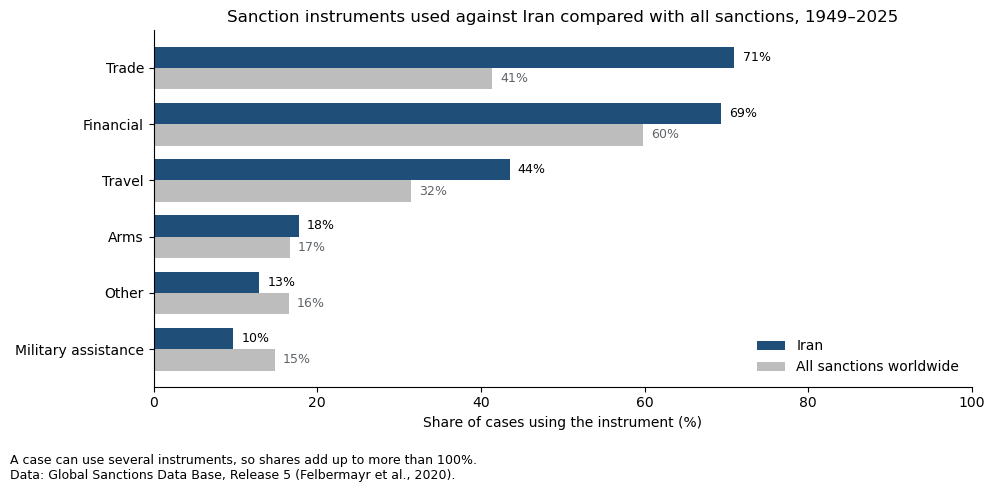

In [7]:
INSTRUMENT_LABELS = {
    "trade": "Trade",
    "financial": "Financial",
    "travel": "Travel",
    "arms": "Arms",
    "military": "Military assistance",
    "other": "Other",
}
instruments = list(INSTRUMENT_LABELS)

# Number and share of cases using each instrument
instrument_table = pd.DataFrame({
    "iran_cases": iran_cases[instruments].sum(),
    "iran_share": iran_cases[instruments].mean().round(3),
    "world_share": r5[instruments].mean().round(3),
}).rename(index=INSTRUMENT_LABELS).sort_values("iran_cases", ascending=False)
display(instrument_table)

# Number of instruments per Iran case
print("Instruments per case:\n", iran_cases[instruments].sum(axis=1).value_counts().sort_index())

# Share of new cases in each period that use the instrument
periods = pd.cut(
    iran_cases["begin_year"],
    bins=[1978, 2005, 2016, 2025],
    labels=["1979–2005", "2006–2016", "2017–2025"],
)
instrument_by_period = (
    iran_cases.groupby(periods, observed=True)[instruments].mean().round(2)
    .rename(columns=INSTRUMENT_LABELS)
)
instrument_by_period.insert(0, "cases", iran_cases.groupby(periods, observed=True).size())
display(instrument_by_period)

# Chart: share of cases using each instrument, Iran vs. world
chart_data = instrument_table[["iran_share", "world_share"]].iloc[::-1] * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(chart_data))
height = 0.38
ax.barh([i + height / 2 for i in y], chart_data["iran_share"], height, color=COLOR_MAIN, label="Iran")
ax.barh([i - height / 2 for i in y], chart_data["world_share"], height, color=COLOR_WORLD, label="All sanctions worldwide")

for i, (iran, world) in enumerate(zip(chart_data["iran_share"], chart_data["world_share"])):
    ax.text(iran + 1, i + height / 2, f"{iran:.0f}%", va="center", fontsize=9)
    ax.text(world + 1, i - height / 2, f"{world:.0f}%", va="center", fontsize=9, color=COLOR_DARK)

ax.set_yticks(list(y))
ax.set_yticklabels(chart_data.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of cases using the instrument (%)")
ax.set_title("Sanction instruments used against Iran compared with all sanctions, 1949–2025")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

fig.text(
    0.01,
    -0.02,
    "A case can use several instruments, so shares add up to more than 100%.\n" + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)

plt.tight_layout()
fig.savefig(IMAGES_DIR / "instruments.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Instruments over time: Iran vs. world

Share of cases in force that use each instrument. Shares are only shown for years with at least five cases in force,
so the charts start in 2006.

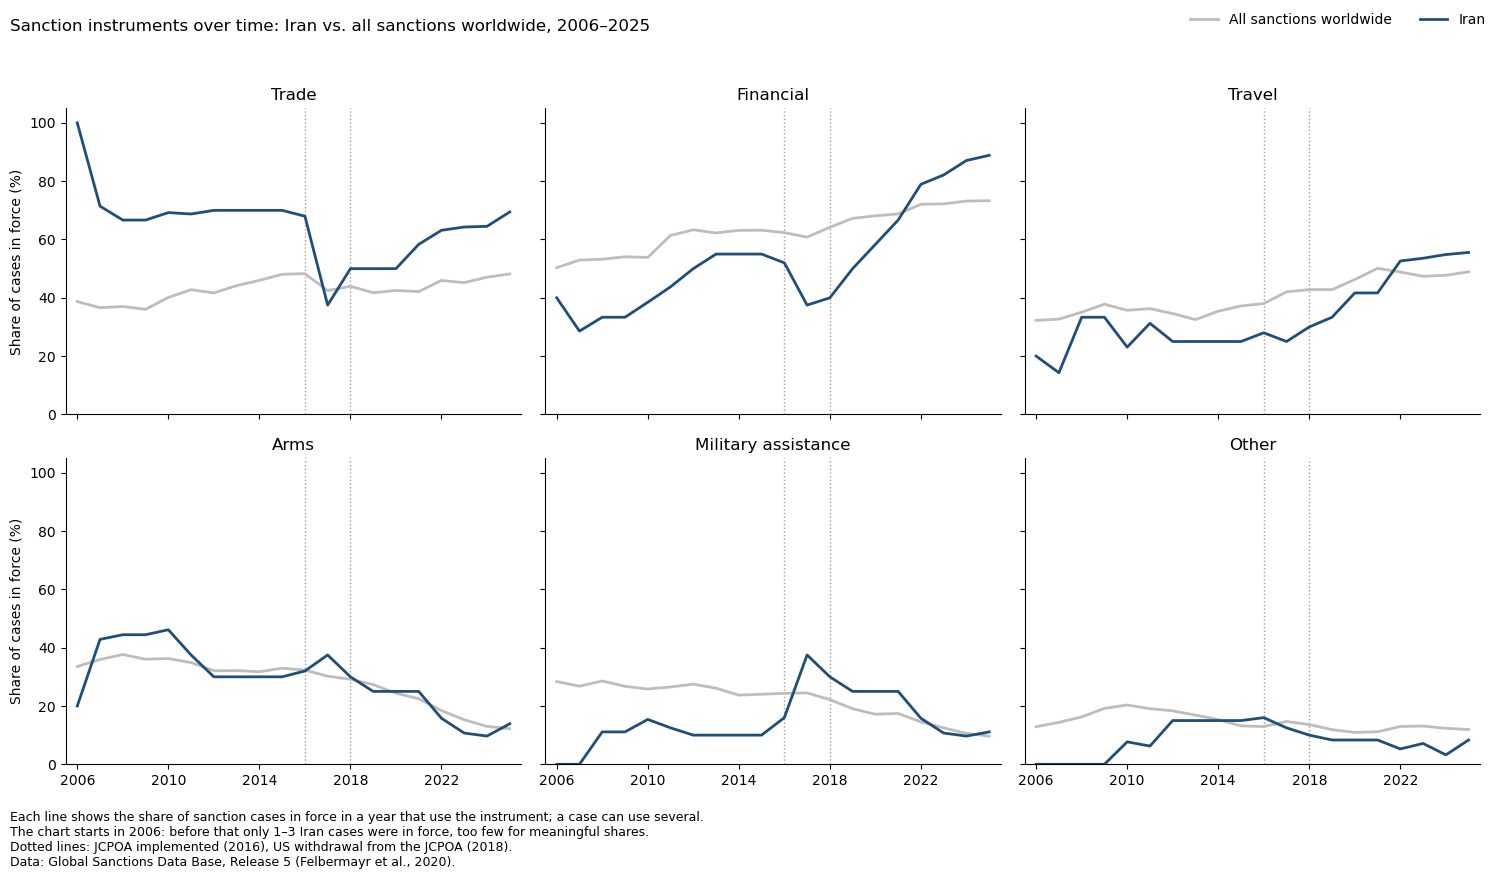

In [8]:
def share_in_force(cases, years):
    """Share of cases in force per year that use each instrument (only with at least 5 cases)."""
    rows = {}
    for y in years:
        active = cases[(cases["begin_year"] <= y) & (cases["end_year"] >= y)]
        rows[y] = (
            active[instruments].mean() * 100
            if len(active) >= 5
            else pd.Series(float("nan"), index=instruments)
        )
    return pd.DataFrame(rows).T.rename(columns=INSTRUMENT_LABELS)


share_years = range(2006, 2026)
iran_share = share_in_force(iran_cases, share_years)
world_share = share_in_force(r5, share_years)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for ax, name in zip(axes.flat, INSTRUMENT_LABELS.values()):
    # Reference lines: JCPOA implemented (2016), US withdrawal (2018)
    for year in (2016, 2018):
        ax.axvline(year, color="#9e9e9e", linestyle=":", linewidth=1)
    ax.plot(world_share.index, world_share[name], color=COLOR_WORLD, linewidth=2, label="All sanctions worldwide")
    ax.plot(iran_share.index, iran_share[name], color=COLOR_MAIN, linewidth=2, label="Iran")
    ax.set_title(name)
    ax.set_ylim(0, 105)
    ax.set_xticks(range(2006, 2026, 4))
    ax.set_xlim(2005.5, 2025.5)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("Share of cases in force (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False, ncol=2)
fig.suptitle("Sanction instruments over time: Iran vs. all sanctions worldwide, 2006–2025", x=0.01, ha="left")

fig.text(
    0.01,
    -0.01,
    "Each line shows the share of sanction cases in force in a year that use the instrument; a case can use several.\n"
    "The chart starts in 2006: before that only 1–3 Iran cases were in force, too few for meaningful shares.\n"
    "Dotted lines: JCPOA implemented (2016), US withdrawal from the JCPOA (2018).\n" + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)

plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Interpretation**
- **Trade** sanctions are far more common against Iran than worldwide (71% vs. 41% of cases); until 2005 every Iran case included them.
- **Financial** sanctions grew from one in three new cases (1979–2005) to almost nine in ten (2017–2025).
  Since 2022 their share is above the global level (2021: 67% vs. 69%; 2025: 89% vs. 73%).
- **Travel** sanctions start in 2006 and exceed the global share from 2022, mostly measures against individuals after the protests.
- **Arms** sanctions mattered mainly during the nuclear dispute (2006–2016) and otherwise follow the global pattern.
- Most cases combine instruments: 43 of 62 cases use at least two.

### 6.3 Financial sanctions in detail (GSDB-FS)

GSDB-FS splits the financial component into six subtypes. A case can carry several.
The subtypes are not stored in a fixed order, so each subtype is tested for presence.

,iran_cases,iran_share,world_share
Asset freeze,37,0.860,0.618
Financial services,35,0.814,0.456
Investment restrictions,11,0.256,0.118
Other,4,0.093,0.019
Payment infrastructure (e.g. SWIFT),2,0.047,0.017
Aid,2,0.047,0.325


,financial_cases,Asset freeze,Financial services,Investment restrictions,Payment infrastructure (e.g. SWIFT),Aid,Other
begin_year,,,,,,,
1979–2005,2,1,0,0,0,1,0
2006–2016,12,8,8,7,1,0,2
2017–2025,29,28,27,4,1,1,2


,case_id,sanctioning_state,begin_year,end_year,descr_financial
472,941,"EU, Croatia, Macedonia, Montenegro, Iceland, A...",2012,2016,"investment_restrictions, financial_services, p..."
1026,1732,EU,2025,2025,"investment_restrictions, financial_services, p..."


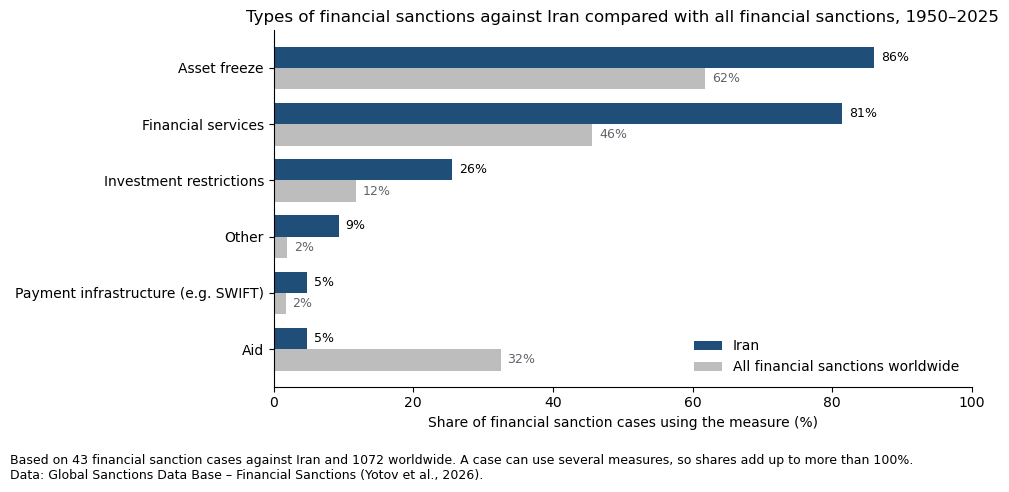

In [9]:
SUBTYPE_LABELS = {
    "asset_freeze": "Asset freeze",
    "financial_services": "Financial services",
    "investment_restrictions": "Investment restrictions",
    "payment_service_infrastructure": "Payment infrastructure (e.g. SWIFT)",
    "aid": "Aid",
    "other": "Other",
}
subtypes = list(SUBTYPE_LABELS)


def add_subtype_flags(df):
    """One 0/1 column per financial subtype (presence test, as order and separator vary)."""
    df = df.copy()
    for code in subtypes:
        df[code] = df["descr_financial"].str.contains(code, regex=False).astype(int)
    return df


fs_iran_flags = add_subtype_flags(fs_iran)
fs_world_flags = add_subtype_flags(fs)

# Number and share of financial cases using each subtype
subtype_table = pd.DataFrame({
    "iran_cases": fs_iran_flags[subtypes].sum(),
    "iran_share": fs_iran_flags[subtypes].mean().round(3),
    "world_share": fs_world_flags[subtypes].mean().round(3),
}).rename(index=SUBTYPE_LABELS).sort_values("iran_cases", ascending=False)
display(subtype_table)

# Number of new financial cases per period and subtype
fs_periods = pd.cut(
    fs_iran_flags["begin_year"],
    bins=[1978, 2005, 2016, 2025],
    labels=["1979–2005", "2006–2016", "2017–2025"],
)
subtype_by_period = (
    fs_iran_flags.groupby(fs_periods, observed=True)[subtypes].sum()
    .rename(columns=SUBTYPE_LABELS)
)
subtype_by_period.insert(0, "financial_cases", fs_iran_flags.groupby(fs_periods, observed=True).size())
display(subtype_by_period)

# Cases with payment infrastructure restrictions (e.g. SWIFT)
swift_cases = fs_iran_flags[fs_iran_flags["payment_service_infrastructure"] == 1]
display(swift_cases[["case_id", "sanctioning_state", "begin_year", "end_year", "descr_financial"]])

# Chart: share of financial cases using each subtype, Iran vs. world
chart_data = subtype_table[["iran_share", "world_share"]].iloc[::-1] * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(chart_data))
height = 0.38
ax.barh([i + height / 2 for i in y], chart_data["iran_share"], height, color=COLOR_MAIN, label="Iran")
ax.barh([i - height / 2 for i in y], chart_data["world_share"], height, color=COLOR_WORLD, label="All financial sanctions worldwide")

for i, (iran, world) in enumerate(zip(chart_data["iran_share"], chart_data["world_share"])):
    ax.text(iran + 1, i + height / 2, f"{iran:.0f}%", va="center", fontsize=9)
    ax.text(world + 1, i - height / 2, f"{world:.0f}%", va="center", fontsize=9, color=COLOR_DARK)

ax.set_yticks(list(y))
ax.set_yticklabels(chart_data.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of financial sanction cases using the measure (%)")
ax.set_title("Types of financial sanctions against Iran compared with all financial sanctions, 1950–2025")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

fig.text(
    0.01,
    -0.02,
    f"Based on {len(fs_iran_flags)} financial sanction cases against Iran and {len(fs_world_flags)} worldwide. "
    "A case can use several measures, so shares add up to more than 100%.\n" + DATA_NOTE_FS,
    fontsize=9,
    va="top",
)

plt.tight_layout()
fig.savefig(IMAGES_DIR / "financial_measures.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**
- Financial sanctions against Iran act mainly on the banking side: **asset freezes** (86%) and bans on
  **financial services** (81%) are far more common than worldwide (62% and 46%).
- **Aid** cuts play almost no role (5% vs. 32% worldwide), as Iran receives little Western development aid.
- **Investment restrictions** were concentrated in the nuclear-dispute period (7 of 11 cases in 2006–2016).
- **Exclusion from payment infrastructure (SWIFT)** occurs in only two cases, both by the EU:
  case 941 (2012–2016) and case 1732 (2025, after the UN sanctions were reimposed).
- Since 2017, 28 of 29 new financial cases include asset freezes, typically against designated persons and entities.

## 7. Objectives and outcomes

GSDB records the declared objectives of each case (up to three) and one outcome per objective.
Outcomes exist only for ended cases; cases still in force are marked `ongoing`.

status
Ongoing    36
Ended      26
Name: count, dtype: int64 



outcome,Failed,Full success,Partial success,Total
objective,,,,
Human rights,4,0,0,4
Nuclear / threat to peace,2,14,1,17
Other,0,1,0,1
Policy change,1,1,0,2
Terrorism,6,0,0,6
Total,13,16,1,30


,Iran,World
outcome,,
Full success,0.533,0.410
Partial success,0.033,0.199
Negotiated settlement,0.000,0.083
Failed,0.433,0.308


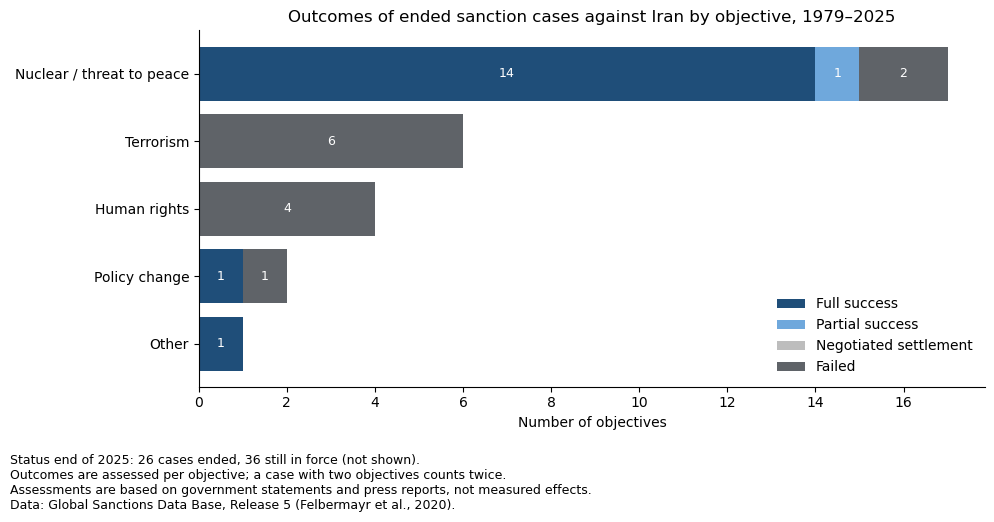

In [10]:
OUTCOME_LABELS = {
    "success_total": "Full success",
    "success_part": "Partial success",
    "nego_settlement": "Negotiated settlement",
    "failed": "Failed",
}
OBJECTIVE_LABELS = {
    "prevent_war": "Nuclear / threat to peace",
    "terrorism": "Terrorism",
    "human_rights": "Human rights",
    "policy_change": "Policy change",
    "end_war": "End war",
    "democracy": "Democracy",
    "destab_regime": "Destabilise regime",
    "territorial_conflict": "Territorial conflict",
    "other": "Other",
}

# Case status at the end of 2025
iran_cases["status"] = iran_cases["ongoing"].map({True: "Ongoing", False: "Ended"})
print(iran_cases["status"].value_counts(), "\n")


def outcomes_per_objective(cases):
    """One row per objective of ended cases, paired with its outcome by position."""
    ended = cases[~cases["success"].str.contains("ongoing")]
    rows = ended.assign(
        objective=ended["objective"].str.split(","),
        outcome=ended["success"].str.split(","),
    ).explode(["objective", "outcome"]).reset_index(drop=True)
    rows["objective"] = rows["objective"].str.strip()
    rows["outcome"] = rows["outcome"].str.strip().map(OUTCOME_LABELS)
    return rows


iran_outcomes = outcomes_per_objective(iran_cases)
world_outcomes = outcomes_per_objective(r5)

# Outcomes of ended Iran cases per objective
outcome_table = pd.crosstab(
    iran_outcomes["objective"].map(OBJECTIVE_LABELS),
    iran_outcomes["outcome"],
    margins=True,
    margins_name="Total",
)
display(outcome_table)

# Share of outcomes: Iran vs. all sanctions worldwide
outcome_comparison = pd.DataFrame({
    "Iran": iran_outcomes["outcome"].value_counts(normalize=True),
    "World": world_outcomes["outcome"].value_counts(normalize=True),
}).reindex(OUTCOME_LABELS.values()).fillna(0).round(3)
display(outcome_comparison)

# Chart: outcomes per objective (ended cases only)
order = ["Full success", "Partial success", "Negotiated settlement", "Failed"]
colors = [COLOR_MAIN, COLOR_LIGHT, COLOR_WORLD, COLOR_DARK]
chart_data = (
    pd.crosstab(iran_outcomes["objective"].map(OBJECTIVE_LABELS), iran_outcomes["outcome"])
    .reindex(columns=order, fill_value=0)
    .loc[lambda df: df.sum(axis=1).sort_values().index]
)

fig, ax = plt.subplots(figsize=(10, 4.5))
left = pd.Series(0, index=chart_data.index)
for outcome, color in zip(order, colors):
    values = chart_data[outcome]
    ax.barh(chart_data.index, values, left=left, color=color, label=outcome)
    for y, (v, l) in enumerate(zip(values, left)):
        if v > 0:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", color="white", fontsize=9)
    left += values

ax.set_title("Outcomes of ended sanction cases against Iran by objective, 1979–2025")
ax.set_xlabel("Number of objectives")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

fig.text(
    0.01,
    -0.02,
    f"Status end of 2025: {(~iran_cases['ongoing']).sum()} cases ended, "
    f"{iran_cases['ongoing'].sum()} still in force (not shown).\n"
    "Outcomes are assessed per objective; a case with two objectives counts twice.\n"
    "Assessments are based on government statements and press reports, not measured effects.\n" + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)

plt.tight_layout()
fig.savefig(IMAGES_DIR / "outcomes.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**
- At the end of 2025, **36 of 62 cases are still in force**; 26 have ended, with 30 assessed objectives.
- **Terrorism and human rights: all 10 assessed objectives failed.**
- **Nuclear / threat to peace:** 14 of 17 objectives are coded as *full success*. These are almost all the nuclear
  sanctions lifted in 2016 under the JCPOA. **This rating should be read with great caution:**
  - the outcome is assessed when a case ends, not over the long term;
  - the US reimposed its sanctions in 2018 and the UN reimposed theirs in 2025 (case 1733);
  - the nuclear dispute was therefore not resolved, even though the earlier cases count as successes.
- Without these JCPOA cases, the record of sanctions against Iran consists mainly of failed objectives.
- Iran shows almost no intermediate outcomes (1 partial success, no negotiated settlement),
  while worldwide 28% of assessed objectives end in one of these two categories.

## 8. Iran in the global context

### 8.1 Most sanctioned countries

Cases per target country, split by objective. Cases with several targets count for each target;
a case with two objectives counts in both objective columns.

In [11]:
# One row per case, target and objective
targets = r5.assign(
    target=r5["sanctioned_state"].apply(split_parties),
    objective=r5["objective"].str.split(","),
).explode("target").explode("objective")
targets["objective"] = targets["objective"].str.strip()

total_per_target = targets.groupby("target")["case_id"].nunique().rename("total_cases")
objective_per_target = targets.groupby(["target", "objective"])["case_id"].nunique().unstack(fill_value=0)

target_table = (
    pd.concat([total_per_target, objective_per_target], axis=1)
    .sort_values("total_cases", ascending=False)
)
target_table.insert(0, "rank", range(1, len(target_table) + 1))

# Top 10 sanctioned countries, Iran highlighted
display(
    target_table.head(10).style.apply(
        lambda row: ["background-color: #dbe7f3" if row.name == "Iran" else "" for _ in row],
        axis=1,
    )
)

# Iran's rank per objective among all targets
for col in ["prevent_war", "terrorism", "human_rights", "policy_change"]:
    rank = target_table[col].rank(ascending=False, method="min")["Iran"]
    print(f"{col}: Iran rank {int(rank)} ({target_table.loc['Iran', col]} cases)")

,rank,total_cases,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism
target,,,,,,,,,,,
Russia,1,75,3,0,41,11,5,30,5,2,0
Iran,2,62,1,0,4,15,3,16,24,0,14
China,3,57,2,13,8,17,8,24,1,1,0
Belarus,4,47,21,0,18,23,1,23,0,1,0
Myanmar,5,42,12,0,3,39,3,0,0,0,0
"Korea, North",6,40,1,1,4,2,3,8,30,0,1
Cambodia,7,33,12,9,10,15,6,2,0,0,0
Pakistan,8,33,7,0,6,5,1,3,10,5,3
Israel,9,32,0,0,15,4,0,9,3,3,1


prevent_war: Iran rank 2 (24 cases)
terrorism: Iran rank 3 (14 cases)
human_rights: Iran rank 6 (15 cases)
policy_change: Iran rank 5 (16 cases)


**Interpretation**
- Iran is the **second most sanctioned country** (62 cases) after Russia (75), out of 185 targets.
- Iran has a broad profile: many cases for nuclear / threat to peace (rank 2, after North Korea),
  terrorism (rank 3, after Afghanistan and Lebanon), human rights (rank 6) and policy change (rank 5).
- The Soviet Union (9 cases) is recorded separately from Russia.

### 8.2 Main sanctioning actors

Cases per sender. The EU and the UN are kept as single senders here.

In [12]:
# One row per case and sender
senders = r5.assign(sender=r5["sanctioning_state"].apply(split_parties)).explode("sender")
senders["against_iran"] = senders["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)

sender_table = senders.groupby("sender").agg(
    total_cases=("case_id", "nunique"),
    first_year=("begin_year", "min"),
    last_year=("begin_year", "max"),
    cases_against_iran=("against_iran", "sum"),
)

# Year with the most new cases per sender (earliest year if tied)
cases_per_sender_year = senders.groupby(["sender", "begin_year"])["case_id"].nunique()
sender_table["peak_year"] = cases_per_sender_year.groupby(level=0).idxmax().str[1]
sender_table["cases_in_peak_year"] = cases_per_sender_year.groupby(level=0).max()

# Most active decade per sender
cases_per_decade = (
    senders.assign(decade=senders["begin_year"] // 10 * 10)
    .groupby(["sender", "decade"])["case_id"].nunique()
)
sender_table["peak_decade"] = cases_per_decade.groupby(level=0).idxmax().str[1].astype(str) + "s"

# Cases per objective
sender_objectives = senders.assign(objective=senders["objective"].str.split(",")).explode("objective")
sender_objectives["objective"] = sender_objectives["objective"].str.strip()
objective_per_sender = (
    sender_objectives.groupby(["sender", "objective"])["case_id"].nunique().unstack(fill_value=0)
)

sender_table = sender_table.join(objective_per_sender).sort_values("total_cases", ascending=False)
sender_table.insert(0, "rank", range(1, len(sender_table) + 1))
sender_table["iran_share"] = (sender_table["cases_against_iran"] / sender_table["total_cases"]).round(3)

display(sender_table.head(10))
display(sender_table.loc[["Iran"]])

,rank,total_cases,first_year,last_year,cases_against_iran,peak_year,cases_in_peak_year,peak_decade,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism,iran_share
sender,,,,,,,,,,,,,,,,,,
United States,1,686,1950,2025,25,2023,61,2020s,136,51,73,198,174,116,51,10,87,0.036
EU,2,190,1978,2025,8,2023,18,2020s,61,2,61,83,14,31,10,2,19,0.042
United Kingdom,3,120,1950,2025,5,2021,25,2020s,30,3,33,43,24,21,5,7,11,0.042
UN,4,88,1951,2025,7,1992,5,2000s,9,1,43,22,1,10,21,4,17,0.080
Canada,5,79,1966,2025,8,2023,9,2020s,20,2,10,33,13,8,12,1,3,0.101
Norway,6,62,1966,2025,3,2011,10,2010s,12,0,24,29,4,11,1,0,6,0.048
Russia,7,55,1992,2025,0,2022,9,2020s,0,1,2,2,7,44,1,2,0,0.000
Australia,8,49,1966,2025,4,2024,5,2020s,14,1,6,14,2,12,11,1,1,0.082
Liechtenstein,9,49,1994,2025,3,2011,10,2010s,8,0,23,26,3,6,1,0,6,0.061


,rank,total_cases,first_year,last_year,cases_against_iran,peak_year,cases_in_peak_year,peak_decade,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism,iran_share
sender,,,,,,,,,,,,,,,,,,
Iran,56,5,1952,2023,0,2022,2,2020s,0,0,0,0,0,4,0,0,4,0.0


**Interpretation**
- The **United States** imposed 686 cases, almost as many as the next nine senders combined (741).
- Almost all major senders are most active in the 2020s; exceptions are the UN (2000s) and Norway,
  Liechtenstein and Iceland (2010s), which rank high because they align with EU sanctions.
- Relative to their total, Canada (10%), Australia (8%) and the UN (8%) direct the largest share of their cases at Iran.
- Iran itself imposed 5 cases (rank 56 of 153 senders), see 8.3.

### 8.3 Who sanctions the world?

All sanctioning countries on one map. EU cases are assigned to the member states at the time of imposition;
cases by the UN and other organisations are not shown.

In [13]:
# One row per case and sanctioning country (all cases)
world_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": code}
    for row in r5.itertuples()
    for code in sender_countries(row.sanctioning_state, row.begin_year)
])

world_senders = world_sender_rows.groupby("iso3")["case_id"].nunique().reset_index(name="cases")
world_senders["country"] = coco.convert(world_senders["iso3"].tolist(), src="ISO3", to="name_short")

organisations = [n for n in sender_names if n not in NAME_TO_ISO3 and n != "EU"]
print("Not shown (organisations):", organisations)
print(f"Cases shown on map: {world_sender_rows['case_id'].nunique()} of {len(r5)}")

# Group case counts into classes for a readable colour scale
bins = [0, 5, 20, 50, 100, float("inf")]
class_labels = ["1–5", "6–20", "21–50", "51–100", "100+"]
world_senders["class"] = pd.cut(world_senders["cases"], bins=bins, labels=class_labels)

fig = px.choropleth(
    world_senders.sort_values("cases"),
    locations="iso3",
    color="class",
    hover_name="country",
    hover_data={"cases": True, "iso3": False, "class": False},
    category_orders={"class": class_labels},
    color_discrete_sequence=["#d9d9d9", "#fcae91", "#fb6a4a", "#de2d26", "#a50f15"],
    title="Who sanctions the world? Number of sanction cases imposed per country, 1949–2025",
)
fig.update_geos(
    showframe=False,
    showcoastlines=False,
    projection_type="natural earth",
    lataxis_range=[-58, 90],  # hide Antarctica
    landcolor="#f5f5f5",      # neutral colour for countries without cases
)
fig.update_layout(
    legend_title_text="Cases",
    height=600,
    margin=dict(l=0, r=0, t=50, b=70),
    annotations=[dict(
        x=0, y=-0.1, xref="paper", yref="paper", showarrow=False, align="left",
        text="Grey: countries with only 1–5 cases. "
             "EU cases are assigned to all EU member states at the time of imposition. "
             "Cases by the UN and other organisations are not shown.<br>"
             "Historical states are shown under today's successor state (e.g. Soviet Union → Russia).<br>"
             + DATA_NOTE_R5,
        font=dict(size=10),
    )],
)
fig.show()

# Own cases: country named as sender itself (EU membership not counted)
own_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": NAME_TO_ISO3[p]}
    for row in r5.itertuples()
    for p in split_parties(row.sanctioning_state)
    if p in NAME_TO_ISO3
]).drop_duplicates()
own_cases = own_sender_rows.groupby("iso3")["case_id"].nunique()

# Cases against Iran per sanctioning country (incl. EU membership)
iran_case_ids = set(iran_cases["case_id"])
against_iran = world_sender_rows[world_sender_rows["case_id"].isin(iran_case_ids)].groupby("iso3")["case_id"].nunique()

# Ranking of sanctioning countries (equal case counts share a rank)
sender_ranking = world_senders.sort_values("cases", ascending=False).reset_index(drop=True)
sender_ranking.insert(0, "rank", sender_ranking["cases"].rank(ascending=False, method="min").astype(int))
sender_ranking["own_cases"] = sender_ranking["iso3"].map(own_cases).fillna(0).astype(int)
sender_ranking["via_eu"] = sender_ranking["cases"] - sender_ranking["own_cases"]
sender_ranking["against_iran"] = sender_ranking["iso3"].map(against_iran).fillna(0).astype(int)
sender_ranking = sender_ranking[["rank", "country", "iso3", "cases", "own_cases", "via_eu", "against_iran", "class"]]
display(sender_ranking.head(15))
print("Not countries, listed separately: EU", sender_table.loc["EU", "total_cases"], "cases, UN", sender_table.loc["UN", "total_cases"], "cases")

# Iran as sanctioning country: rank, group and targets
display(sender_ranking[sender_ranking["iso3"] == "IRN"])
display(iran_as_sender[["case_id", "sanctioned_state", "begin_year", "end_year", "objective", "success"]])

Not shown (organisations): ['African Union', 'CSCE', 'ChinCom', 'CoCom', 'Commonwealth', 'ECCAS', 'ECOWAS', 'G7', 'G8', 'Kimberly Process Participants', 'League of Arab States', 'MERCOSUR', 'NAFTA', 'NATO', 'OAPEC', 'OSCE', 'Organisation of African Unity', 'Organization of American States', 'Organization of Eastern Caribbean States', 'Pacific Islands Forum', 'Paris Agreement Signatories', 'SADC', 'UN', 'UNASUR']
Cases shown on map: 1608 of 1794


,rank,country,iso3,cases,own_cases,via_eu,against_iran,class
0,1,United States,USA,686,686,0,25,100+
1,2,United Kingdom,GBR,247,120,127,9,100+
2,3,Germany,DEU,227,38,189,8,100+
3,4,France,FRA,226,37,189,8,100+
4,5,Denmark,DNK,208,18,190,8,100+
5,5,Netherlands,NLD,208,18,190,8,100+
6,7,Spain,ESP,201,12,189,8,100+
7,8,Italy,ITA,198,9,189,8,100+
8,8,Belgium,BEL,198,8,190,8,100+
9,10,Greece,GRC,193,4,189,8,100+


Not countries, listed separately: EU 190 cases, UN 88 cases


,rank,country,iso3,cases,own_cases,via_eu,against_iran,class
58,58,Iran,IRN,5,5,0,0,1–5


,case_id,sanctioned_state,begin_year,end_year,objective,success
29,30,United Kingdom,1952,1953,policy_change,nego_settlement
703,704,Argentina,2003,2007,terrorism,success_total
1350,1351,Canada,2022,2025,"policy_change,terrorism","ongoing,ongoing"
1442,1443,United States,2022,2025,"policy_change,terrorism","ongoing,ongoing"
1473,1474,EU,2023,2025,"policy_change,terrorism","ongoing,ongoing"


### 8.4 The EU as a sanctioning actor

The EU is the second largest sanctioning actor in the world after the United States.
This section looks at EU sanctions overall and then at the EU cases against Iran.

EU cases: 190 (rank 2 of 153 senders)
   ongoing at the end of 2025: 92
   first case: 1978


,new_cases
begin_year,
1970s,1
1990s,38
2000s,43
2010s,45
2020s,63


,rank,cases
target,,
Belarus,1,12
Russia,2,11
Iran,3,8
Myanmar,3,8
Afghanistan,5,6
China,5,6
Sudan,5,6
"Congo, Democratic Republic of the",5,6
Burundi,9,5


,cases
objective,
Human rights,83
Democracy,61
End war,61
Policy change,31
Terrorism,19
Other,14
Nuclear / threat to peace,10
Destabilise regime,2
Territorial conflict,2


,eu_share,world_share
Trade,0.316,0.414
Financial,0.768,0.598
Travel,0.495,0.315
Arms,0.279,0.166
Military assistance,0.189,0.148
Other,0.116,0.165


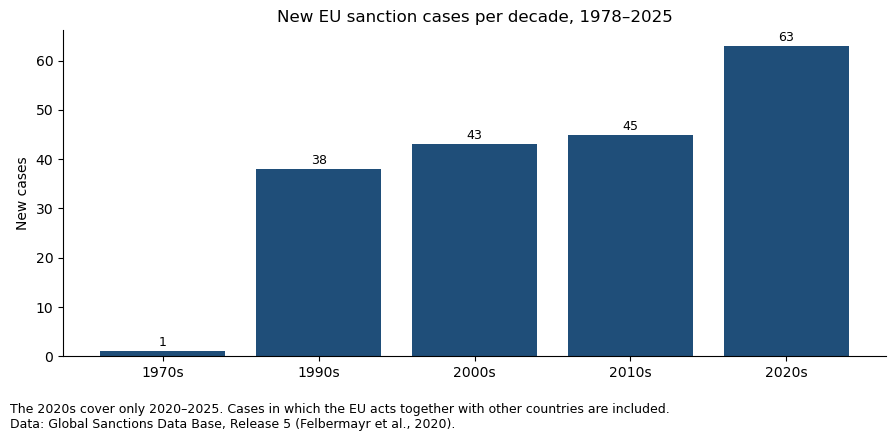

In [14]:
# All EU cases (EU named as sender, alone or together with other countries)
eu_cases = senders[senders["sender"] == "EU"].drop_duplicates("case_id").copy()
eu_cases["ongoing"] = eu_cases["success"].str.contains("ongoing")

print("EU cases:", len(eu_cases), f"(rank {sender_table.loc['EU', 'rank']} of {len(sender_table)} senders)")
print("   ongoing at the end of 2025:", eu_cases["ongoing"].sum())
print("   first case:", eu_cases["begin_year"].min())

# New EU cases per decade
eu_per_decade = eu_cases.groupby(eu_cases["begin_year"] // 10 * 10).size()
eu_per_decade.index = eu_per_decade.index.astype(str) + "s"
display(eu_per_decade.rename("new_cases").to_frame())

# Main targets of EU sanctions (cases with several targets count for each target)
eu_targets = (
    eu_cases.assign(target=eu_cases["sanctioned_state"].apply(split_parties))
    .explode("target")["target"].value_counts()
)
eu_top_targets = eu_targets.head(10).rename("cases").to_frame()
eu_top_targets.insert(0, "rank", eu_targets.rank(ascending=False, method="min").astype(int).head(10))
display(
    eu_top_targets.style.apply(
        lambda row: ["background-color: #dbe7f3" if row.name == "Iran" else "" for _ in row],
        axis=1,
    )
)

# Objectives of EU sanctions (a case with two objectives counts twice)
eu_objectives = eu_cases["objective"].str.split(",").explode().str.strip().map(
    lambda o: OBJECTIVE_LABELS.get(o, o)
)
display(eu_objectives.value_counts().rename("cases").to_frame())

# Instruments used by the EU compared with all sanctions worldwide
eu_instruments = pd.DataFrame({
    "eu_share": eu_cases[instruments].mean().round(3),
    "world_share": r5[instruments].mean().round(3),
}).rename(index=INSTRUMENT_LABELS)
display(eu_instruments)

# Chart: new EU cases per decade
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(eu_per_decade.index, eu_per_decade.values, color=COLOR_MAIN)
for x, v in zip(eu_per_decade.index, eu_per_decade.values):
    ax.text(x, v + 1, str(v), ha="center", fontsize=9)
ax.set_title("New EU sanction cases per decade, 1978–2025")
ax.set_ylabel("New cases")
ax.spines[["top", "right"]].set_visible(False)
fig.text(
    0.01,
    -0.02,
    "The 2020s cover only 2020–2025. Cases in which the EU acts together with other countries are included.\n"
    + DATA_NOTE_R5,
    fontsize=9,
    va="top",
)
plt.tight_layout()
plt.show()

**Interpretation**
- The EU has imposed **190 cases** since 1978 (rank 2 after the US); 92 were still in force at the end of 2025.
- Almost all EU sanctions date from 1990 onwards, with the highest number of new cases in the 2020s.
- The EU sanctions mainly for human rights, democracy and ending wars, and uses financial (77% vs. 60%), travel
  (50% vs. 32%) and arms measures (28% vs. 17%) more often than the global average, trade measures less often (32% vs. 41%).
- Its main targets are Belarus (12) and Russia (11), followed by Myanmar and Iran (8 each).

**EU sanctions against Iran**

In [15]:
# EU cases against Iran with objective, outcome and instruments
eu_iran = eu_cases[eu_cases["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()
eu_iran["instruments"] = eu_iran[instruments].apply(
    lambda row: ", ".join(INSTRUMENT_LABELS[i] for i in instruments if row[i] == 1), axis=1
)
eu_iran = eu_iran.merge(fs[["case_id", "descr_financial"]], on="case_id", how="left")

print("EU cases against Iran:", len(eu_iran), "of", len(iran_cases), "Iran cases")
display(
    eu_iran[["case_id", "begin_year", "end_year", "objective", "success", "instruments", "descr_financial"]]
    .sort_values("begin_year")
    .reset_index(drop=True)
)

EU cases against Iran: 8 of 62 Iran cases


,case_id,begin_year,end_year,objective,success,instruments,descr_financial
0,806,2007,2016,prevent_war,success_total,Arms,NaN
1,901,2011,2016,human_rights,failed,"Financial, Travel",asset_freeze
2,940,2012,2016,human_rights,failed,Trade,NaN
3,941,2012,2016,policy_change,failed,"Trade, Financial, Other","investment_restrictions, financial_services, p..."
4,1372,2022,2025,human_rights,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
5,1373,2022,2025,end_war,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
6,1489,2023,2025,policy_change,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
7,1732,2025,2025,policy_change,ongoing,"Trade, Financial, Travel, Arms, Other","investment_restrictions, financial_services, p..."


**Interpretation**
- The EU imposed **8 of the 62 cases** against Iran, in two waves: 2007–2012 (nuclear programme, human rights,
  policy change) and 2022–2025 (protest crackdown, drone deliveries to Russia, return of the UN sanctions).
- The four cases of the first wave ended in 2016: the nuclear case is coded as a success, the three others as failed.
  The four cases since 2022 are still in force.
- Both exclusions from payment infrastructure (SWIFT) against Iran were imposed by the EU, in 2012 and 2025.

### 8.5 Germany as a sanctioning actor

On the map, Germany ranks **third worldwide (227 cases)**, after the US and the UK (227 includes one case of the former GDR;
without it, Germany and France share rank 3 with 226 cases each). Most of this comes from
EU sanctions, which Germany decides together with the other member states. The next cell separates Germany's own
national cases.

In [16]:
# Germany's own cases (named as sender, alone or with other countries; EU cases excluded)
germany_own = senders[senders["sender"] == "Germany"].drop_duplicates("case_id")
germany_rank = sender_ranking.loc[sender_ranking["iso3"] == "DEU", ["rank", "cases"]]

print("Germany, rank and cases incl. EU:", germany_rank.to_dict("records"))
print("Germany, own national cases:", len(germany_own))
print("   of which against Iran:", germany_own["sanctioned_state"].str.contains(IRAN_PATTERN, na=False).sum())
print("   first and last year:", germany_own["begin_year"].min(), "–", germany_own["begin_year"].max())

# Sanctions against Israel: which EU actors appear as senders?
eu_names = {"EU", "Germany"} | {
    name for name, iso in NAME_TO_ISO3.items() if iso in EU_MEMBERS and iso != "GBR"
}
israel_cases = senders[senders["sanctioned_state"].str.contains(r"\bIsrael\b", na=False)]
israel_eu = israel_cases[israel_cases["sender"].isin(eu_names)]

print("\nCases against Israel (all senders):", israel_cases["case_id"].nunique())
print("   by the EU:", (israel_cases["sender"] == "EU").sum())
print("   by Germany:", (israel_cases["sender"] == "Germany").sum())
display(israel_eu[["case_id", "sender", "begin_year", "objective"]].sort_values("begin_year"))

Germany, rank and cases incl. EU: [{'rank': 3, 'cases': 227}]
Germany, own national cases: 37
   of which against Iran: 0
   first and last year: 1949 – 2025

Cases against Israel (all senders): 32
   by the EU: 0
   by Germany: 0


,case_id,sender,begin_year,objective
15,16,France,1950,prevent_war
127,128,France,1967,territorial_conflict
1006,1007,Spain,2014,prevent_war
1739,1740,Netherlands,2025,policy_change
1743,1744,Slovenia,2025,end_war
1744,1745,Spain,2025,end_war


**Interpretation**
- Germany has **37 national cases** of its own (1949–2025), **none against Iran**. Against Iran, Germany acts through the EU
  (8 cases) and as part of the E3 with France and the UK: in August 2025 the E3 triggered the return of the
  UN sanctions against Iran ("snapback"), recorded in the data as UN case 1733.
- After the period covered by the data, Germany strongly backed the EU's designation of the Revolutionary Guards (IRGC)
  as a terrorist organisation: EU foreign ministers reached political agreement on 29 January 2026, and the Council
  formally added the IRGC to the EU terrorist list on 19 February 2026.
- For comparison: the data records no case against Israel by the EU or by Germany; national measures against Israel
  were taken by some EU member states (France 1950 and 1967, Spain 2014 and 2025, the Netherlands and Slovenia 2025).
  A proposal by Spain, Slovenia and Ireland to suspend the EU-Israel Association Agreement was not adopted in April 2026
  after Germany and Italy opposed it.

### 8.6 Comparison with non-Western countries

The same indicators for China, Russia (incl. the Soviet Union), Saudi Arabia, India, Turkey and Iran as senders.

In [17]:
compare = {
    "China": "CHN", "Russia": "RUS", "Saudi Arabia": "SAU",
    "India": "IND", "Turkey": "TUR", "Iran": "IRN",
}

# Senders whose cases are counted for each country (Russia includes the Soviet Union)
sender_aliases = {"Russia": ["Russia", "Soviet Union"]}

comparison_rows = []
for country, iso in compare.items():
    names = sender_aliases.get(country, [country])
    cases = senders[senders["sender"].isin(names)].drop_duplicates("case_id")
    case_targets = cases.assign(target=cases["sanctioned_state"].apply(split_parties)).explode("target")
    case_objectives = cases["objective"].str.split(",").explode().str.strip()
    ranking_row = sender_ranking[sender_ranking["iso3"] == iso]

    comparison_rows.append({
        "country": country,
        "world_rank": int(ranking_row["rank"].iloc[0]) if len(ranking_row) else None,
        "cases": len(cases),
        "first_year": cases["begin_year"].min(),
        "last_year": cases["begin_year"].max(),
        "peak_year": cases["begin_year"].value_counts().idxmax() if len(cases) else None,
        "ongoing": int(cases["success"].str.contains("ongoing").sum()),
        "against_iran": int(cases["sanctioned_state"].str.contains(IRAN_PATTERN, na=False).sum()),
        "top_targets": ", ".join(f"{t} ({n})" for t, n in case_targets["target"].value_counts().head(3).items()),
        "top_objectives": ", ".join(f"{o} ({n})" for o, n in case_objectives.value_counts().head(3).items()),
    })

comparison_table = pd.DataFrame(comparison_rows).set_index("country")
display(comparison_table)

,world_rank,cases,first_year,last_year,peak_year,ongoing,against_iran,top_targets,top_objectives
country,,,,,,,,,
China,45,27,1967,2025,2021,16,0,"United States (5), Canada (3), Taiwan (3)","policy_change (20), human_rights (2), other (2)"
Russia,31,67,1950,2025,2022,30,0,"Australia (5), Ukraine (5), United Kingdom (5)","policy_change (52), other (8), territorial_con..."
Saudi Arabia,54,9,1990,2025,1990,2,0,"Lebanon (2), Palestine (1), Yemen, North (1)","policy_change (4), terrorism (4), democracy (1)"
India,50,16,1949,2025,1954,2,0,"Pakistan (5), Portugal (5), Nepal (4)","territorial_conflict (6), democracy (4), polic..."
Turkey,47,26,1985,2024,2011,13,0,"Afghanistan (5), Somalia (3), Sudan (2)","end_war (15), human_rights (13), terrorism (6)"
Iran,58,5,1952,2023,2022,3,0,"United Kingdom (1), Argentina (1), Canada (1)","policy_change (4), terrorism (4)"


**Interpretation**
- **None of these countries appears as a sender of a case against Iran.** All national and EU sanctions against Iran
  come from Western or Western-aligned countries and Djibouti. UN measures are counted separately as UN cases
  (7 against Iran); UN member states such as China are obliged to implement them.
- China and Russia sanction almost exclusively for *policy change*, often as counter-measures
  (China against the US and Canada, Russia against Australia, Estonia and Ukraine).
- Turkey follows a pattern closer to Western senders (ending wars, human rights); 18 of its 26 cases were imposed
  together with the EU.
- India was mainly active early on (peak year 1954; Portugal over Goa, Pakistan).
- Iran itself imposed 5 cases: against the UK (1952–53, oil crisis), Argentina (2003–07), and Canada, the US and the EU (2022–23).

## 9. Export for the dashboard

The Streamlit dashboard (`dashboard/app.py`) reads only the **aggregated tables** exported here: counts and shares,
no individual sanction cases. This keeps the raw GSDB data out of the repository and the deployed dashboard.

In [18]:
import json
from pathlib import Path

export_dir = Path("dashboard/data")
export_dir.mkdir(parents=True, exist_ok=True)

# 4. Development over time
pd.DataFrame({
    "year": list(active_per_year.index),
    "cases_in_force": active_per_year.values,
    "new_cases": new_per_year.reindex(active_per_year.index, fill_value=0).values,
}).to_csv(export_dir / "iran_timeline.csv", index=False)

pd.DataFrame(
    [{"year": year, "event": label} for year, label in KEY_EVENTS.items()]
).to_csv(export_dir / "key_events.csv", index=False)

# 5. Who sanctions Iran
iran_senders.sort_values("cases", ascending=False).to_csv(export_dir / "iran_senders.csv", index=False)
(
    senders[senders["against_iran"]].groupby("sender")["case_id"].nunique()
    .sort_values(ascending=False).rename_axis("sender").reset_index(name="cases")
    .to_csv(export_dir / "iran_sender_actors.csv", index=False)
)

# 6. Instruments
instrument_table.rename_axis("instrument").reset_index().to_csv(export_dir / "iran_instruments.csv", index=False)
instrument_by_period.rename_axis("period").reset_index().to_csv(export_dir / "iran_instruments_by_period.csv", index=False)
pd.concat([
    iran_share.rename_axis("year").reset_index().melt(id_vars="year", var_name="instrument", value_name="share").assign(group="Iran"),
    world_share.rename_axis("year").reset_index().melt(id_vars="year", var_name="instrument", value_name="share").assign(group="World"),
]).round(1).to_csv(export_dir / "instrument_shares_over_time.csv", index=False)
subtype_table.rename_axis("subtype").reset_index().to_csv(export_dir / "financial_subtypes.csv", index=False)
subtype_by_period.rename_axis("period").reset_index().to_csv(export_dir / "financial_subtypes_by_period.csv", index=False)

# 7. Objectives and outcomes
(
    iran_outcomes.assign(objective=iran_outcomes["objective"].map(OBJECTIVE_LABELS))
    .groupby(["objective", "outcome"]).size().reset_index(name="count")
    .to_csv(export_dir / "iran_outcomes.csv", index=False)
)
outcome_comparison.rename_axis("outcome").reset_index().to_csv(export_dir / "outcome_comparison.csv", index=False)

# 8. Global context
target_table.head(15).rename_axis("target").reset_index().to_csv(export_dir / "top_targets.csv", index=False)
sender_table.head(15).rename_axis("sender").reset_index().to_csv(export_dir / "top_senders.csv", index=False)
sender_ranking.head(15).to_csv(export_dir / "top_sender_countries.csv", index=False)
world_senders.to_csv(export_dir / "world_senders.csv", index=False)
eu_per_decade.rename_axis("decade").reset_index(name="new_cases").to_csv(export_dir / "eu_per_decade.csv", index=False)
eu_targets.head(10).rename_axis("target").reset_index(name="cases").to_csv(export_dir / "eu_top_targets.csv", index=False)
eu_objectives.value_counts().rename_axis("objective").reset_index(name="cases").to_csv(export_dir / "eu_objectives.csv", index=False)
eu_instruments.rename_axis("instrument").reset_index().to_csv(export_dir / "eu_instruments.csv", index=False)
comparison_table.reset_index().to_csv(export_dir / "sender_comparison.csv", index=False)

# Headline figures
germany_row = sender_ranking.loc[sender_ranking["iso3"] == "DEU"].iloc[0]
kpis = {
    "cases_world": int(len(r5)),
    "cases_iran": int(len(iran_cases)),
    "share_iran": round(len(iran_cases) / len(r5) * 100, 1),
    "iran_rank_target": int(target_table.loc["Iran", "rank"]),
    "iran_first_year": int(iran_cases["begin_year"].min()),
    "iran_ongoing": int(iran_cases["ongoing"].sum()),
    "iran_ended": int((~iran_cases["ongoing"]).sum()),
    "iran_cases_in_force_2025": int(active_per_year.loc[2025]),
    "iran_cases_by_us": int(sender_table.loc["United States", "cases_against_iran"]),
    "iran_cases_by_eu": int(sender_table.loc["EU", "cases_against_iran"]),
    "iran_financial_cases": int(iran_cases["financial"].sum()),
    "eu_cases": int(len(eu_cases)),
    "un_cases": int(sender_table.loc["UN", "total_cases"]),
    "eu_rank": int(sender_table.loc["EU", "rank"]),
    "eu_ongoing": int(eu_cases["ongoing"].sum()),
    "germany_rank": int(germany_row["rank"]),
    "germany_cases_incl_eu": int(germany_row["cases"]),
    "germany_own_cases": int(len(germany_own)),
}
(export_dir / "kpis.json").write_text(json.dumps(kpis, indent=2))

print("Exported:", sorted(p.name for p in export_dir.iterdir()))

Exported: ['eu_instruments.csv', 'eu_objectives.csv', 'eu_per_decade.csv', 'eu_top_targets.csv', 'financial_subtypes.csv', 'financial_subtypes_by_period.csv', 'instrument_shares_over_time.csv', 'iran_instruments.csv', 'iran_instruments_by_period.csv', 'iran_outcomes.csv', 'iran_sender_actors.csv', 'iran_senders.csv', 'iran_timeline.csv', 'key_events.csv', 'kpis.json', 'outcome_comparison.csv', 'sender_comparison.csv', 'top_sender_countries.csv', 'top_senders.csv', 'top_targets.csv', 'world_senders.csv']


## 10. Key findings

1. **Iran is the second most sanctioned country in the world** (62 cases since 1979), after Russia.
2. **Sanctions came in three phases:** a small US-only regime (1979–2005), a broad multilateral regime during the
   nuclear dispute (2006–2016), and a renewed, wider increase after the US left the JCPOA (2018–2025),
   reaching the highest level of 36 cases in force in 2025.
3. **The senders are almost exclusively Western.** The US alone imposed 25 of 62 cases; China, Russia, India,
   Saudi Arabia and Turkey do not appear as senders of any case against Iran (UN cases are counted separately).
4. **The EU is the second largest sanctioning actor worldwide** (190 cases, mostly since 1990). Iran is among its
   most sanctioned targets (8 cases), and both SWIFT exclusions against Iran were EU measures (2012, 2025).
5. **Germany ranks third worldwide** (227 cases), mainly through EU sanctions. Against Iran it acts through the EU and
   the E3 (France, Germany, UK), which triggered the return of the UN sanctions in 2025.
6. **The instruments shifted from trade to finance.** Financial sanctions rose from one in three new cases (1979–2005)
   to almost nine in ten (2017–2025), dominated by asset freezes and bans on financial services.
7. **Recorded success is limited.** All assessed terrorism and human-rights objectives failed. The nuclear
   "successes" refer to sanctions lifted under the JCPOA in 2016, which were later reimposed by the US (2018) and the UN (2025).

## 11. Limitations

- **Case counts are not a measure of severity.** A comprehensive embargo counts as one case, while a long,
  step-by-step escalation can produce many cases (GSDB codebook, case delineation rules).
- **Outcome ratings are assessments, not measurements.** They are based on government statements and press reports
  and are made at the end of a case. Later developments, such as reimposed sanctions, do not change an earlier rating.
- **Effects are not covered.** GSDB records which measures were imposed, not their economic or humanitarian impact.
  Whether measures described as targeted (e.g. asset freezes against individuals) also affected the wider population
  cannot be assessed with this data.
- **Coverage starts in 1979 for Iran.** Earlier measures, such as during the 1951–53 oil crisis, are not recorded as sanctions against Iran.
- **Coder judgement.** The delineation of cases and the classification of objectives involve judgement by the GSDB team.
- **Data irregularities:** `end_year` is set to 2025 instead of blank for ongoing cases; some recent cases use historical
  country names (*Ceylon*, *South Vietnam*, *Malaya*, *Transjordan*). See section 2.
- **Country attribution on maps:** EU cases are assigned to all member states at the time of imposition; UN and other
  organisations are not shown; historical states appear under their successor state.
- **Small numbers before 2006:** with only 1–3 Iran cases in force, shares for these years are not meaningful.

## 12. Sources

**Data**
- Felbermayr, G., A. Kirilakha, C. Syropoulos, E. Yalcin, and Y. V. Yotov (2020),
  "The Global Sanctions Data Base," *European Economic Review*, 129, 103561. *(GSDB-R5)*
- Yotov, Y. V., G. Felbermayr, H. Kariem, A. Kirilakha, O. Kwon, C. Syropoulos, and E. Yalcin (2026),
  "Financial Sanctions and International Trade: Evidence from a New Database," Working Paper 2026014,
  Center for Global Policy Analysis, LeBow College of Business, Drexel University. *(GSDB-FS)*
- GSDB Team (2026): *Codebook GSDB-R5, Version 1.0* and *Codebook GSDB-FS, Version 1.0*.

**Context (news sources, Germany and the EU)**
- Al-Monitor (28 Aug 2025): [UK, France, Germany trigger snapback sanctions on Iran](https://www.al-monitor.com/originals/2025/08/uk-france-germany-trigger-snapback-sanctions-iran)
- Al Jazeera (13 Aug 2025): [France, Germany and UK say they are ready to reimpose Iran sanctions](https://www.aljazeera.com/news/2025/8/13/france-germany-and-uk-say-they-are-ready-to-reimpose-iran-sanctions)
- Iran International (29 Jan 2026): [Germany backs EU terrorism listing of the IRGC](https://www.iranintl.com/en/202601299777)
- bne IntelliNews (29 Jan 2026): [EU designates Iran's Revolutionary Guards as terrorist organisation](https://www.intellinews.com/eu-designates-iran-s-revolutionary-guards-as-terrorist-organisation-over-protest-crackdown-423007/)
- Eunews (19 Feb 2026): [Iran's Revolutionary Guards officially added to EU terrorist list](https://www.eunews.it/en/2026/02/19/iran-revolutionary-guards-officially-added-to-eu-terrorist-list)
- Al Jazeera (21 Apr 2026): [Germany and Italy block bid to suspend EU-Israel trade pact](https://www.aljazeera.com/news/2026/4/21/spain-slovenia-ireland-push-eu-to-debate-israel-pact-suspension)

**Data access**
The data is available free of charge on request at
[globalsanctionsdatabase.com/data](https://www.globalsanctionsdatabase.com/data/).
Commercial use and redistribution are not permitted; the raw files are therefore not included in this repository.